In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [3]:
df = pd.read_csv('bodyPerformance.csv')

# New Section

In [4]:
df2 = df.copy()
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

5.1 Dataset Overview

In [5]:
# 5.1 Dataset Overview
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("\nColumn names:", df.columns.tolist())
print("\nFirst 5 rows:")
display(df.head())
display(df.tail())

Number of rows: 13393
Number of columns: 12

Column names: ['age', 'gender', 'height_cm', 'weight_kg', 'body fat_%', 'diastolic', 'systolic', 'gripForce', 'sit and bend forward_cm', 'sit-ups counts', 'broad jump_cm', 'class']

First 5 rows:


,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
0,27.0,M,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,C
1,25.0,M,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,A
2,31.0,M,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,C
3,32.0,M,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,B
4,28.0,M,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,B


,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
13388,25.0,M,172.1,71.8,16.2,74.0,141.0,35.8,17.4,47.0,198.0,C
13389,21.0,M,179.7,63.9,12.1,74.0,128.0,33.0,1.1,48.0,167.0,D
13390,39.0,M,177.2,80.5,20.1,78.0,132.0,63.5,16.4,45.0,229.0,A
13391,64.0,F,146.1,57.7,40.4,68.0,121.0,19.3,9.2,0.0,75.0,D
13392,34.0,M,164.0,66.1,19.5,82.0,150.0,35.9,7.1,51.0,180.0,C


In [6]:
# 5.2 Column Understanding
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13393 entries, 0 to 13392
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      13393 non-null  float64
 1   gender                   13393 non-null  object 
 2   height_cm                13393 non-null  float64
 3   weight_kg                13393 non-null  float64
 4   body fat_%               13393 non-null  float64
 5   diastolic                13393 non-null  float64
 6   systolic                 13393 non-null  float64
 7   gripForce                13393 non-null  float64
 8   sit and bend forward_cm  13393 non-null  float64
 9   sit-ups counts           13393 non-null  float64
 10  broad jump_cm            13393 non-null  float64
 11  class                    13393 non-null  object 
dtypes: float64(10), object(2)
memory usage: 1.2+ MB


In [7]:
# 5.3 Data Type Verification
print(df.dtypes)

age                        float64
gender                      object
height_cm                  float64
weight_kg                  float64
body fat_%                 float64
diastolic                  float64
systolic                   float64
gripForce                  float64
sit and bend forward_cm    float64
sit-ups counts             float64
broad jump_cm              float64
class                       object
dtype: object


In [8]:
# 5.4 Missing Values
missing = df.isnull().sum()
print(missing)
print("\nPercentage of missing values:")
print((missing / len(df) * 100).round(2))

age                        0
gender                     0
height_cm                  0
weight_kg                  0
body fat_%                 0
diastolic                  0
systolic                   0
gripForce                  0
sit and bend forward_cm    0
sit-ups counts             0
broad jump_cm              0
class                      0
dtype: int64

Percentage of missing values:
age                        0.0
gender                     0.0
height_cm                  0.0
weight_kg                  0.0
body fat_%                 0.0
diastolic                  0.0
systolic                   0.0
gripForce                  0.0
sit and bend forward_cm    0.0
sit-ups counts             0.0
broad jump_cm              0.0
class                      0.0
dtype: float64


In [9]:
# 5.5 Duplicates
duplicates = df.duplicated().sum()
print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 1


In [10]:
df = df.drop_duplicates()
df.shape[0]

13392

In [11]:
# 5.6 Validity Checks
print("Negative or impossible values:")
print("Age < 0:", (df['age'] < 0).sum())
print("Weight <= 0:", (df['weight_kg'] <= 0).sum())
print("Height <= 0:", (df['height_cm'] <= 0).sum())
print("Body fat > 50%:", (df['body fat_%'] > 50).sum())
print("Blood pressure 0:", ((df['diastolic'] == 0) | (df['systolic'] == 0)).sum())

Negative or impossible values:
Age < 0: 0
Weight <= 0: 0
Height <= 0: 0
Body fat > 50%: 6
Blood pressure 0: 1


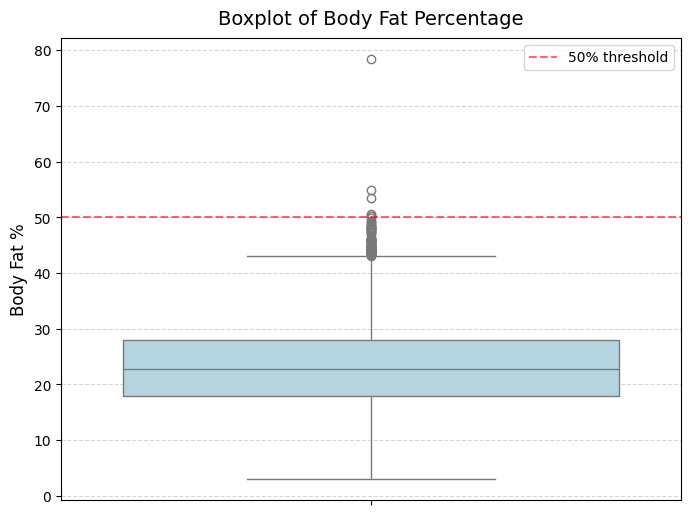

In [12]:
plt.figure(figsize=(8, 6))          # حجم مناسب
sns.boxplot(y=df['body fat_%'], color='lightblue')

plt.title('Boxplot of Body Fat Percentage', fontsize=14, pad=10)
plt.ylabel('Body Fat %', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# خط أفقي عند 50% عشان نشوف القيم المشبوهة بوضوح
plt.axhline(y=50, color='red', linestyle='--', alpha=0.6, label='50% threshold')
plt.legend()

plt.show()

In [13]:
# Remove rows where body fat > 50 OR systolic is NaN OR diastolic is NaN
clean = (df['body fat_%'] >= 50) | df['systolic'].isna() | df['diastolic'].isna()

df_clean = df[~clean].copy()

print("Rows before:", len(df))
print("Rows after :", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

Rows before: 13392
Rows after : 13386
Rows removed: 6


In [14]:
# 5.7 Univariate Analysis
numeric_cols = df.select_dtypes(include=np.number).columns
summary = df[numeric_cols].describe().round(2)
print(summary)

            age  height_cm  weight_kg  body fat_%  diastolic  systolic  \
count  13392.00   13392.00   13392.00    13392.00   13392.00  13392.00   
mean      36.78     168.56      67.45       23.24      78.80    130.24   
std       13.63       8.43      11.95        7.26      10.74     14.71   
min       21.00     125.00      26.30        3.00       0.00      0.00   
25%       25.00     162.40      58.20       18.00      71.00    120.00   
50%       32.00     169.20      67.40       22.80      79.00    130.00   
75%       48.00     174.80      75.30       28.00      86.00    141.00   
max       64.00     193.80     138.10       78.40     156.20    201.00   

       gripForce  sit and bend forward_cm  sit-ups counts  broad jump_cm  
count   13392.00                 13392.00        13392.00       13392.00  
mean       36.96                    15.21           39.77         190.13  
std        10.62                     8.46           14.28          39.87  
min         0.00                 

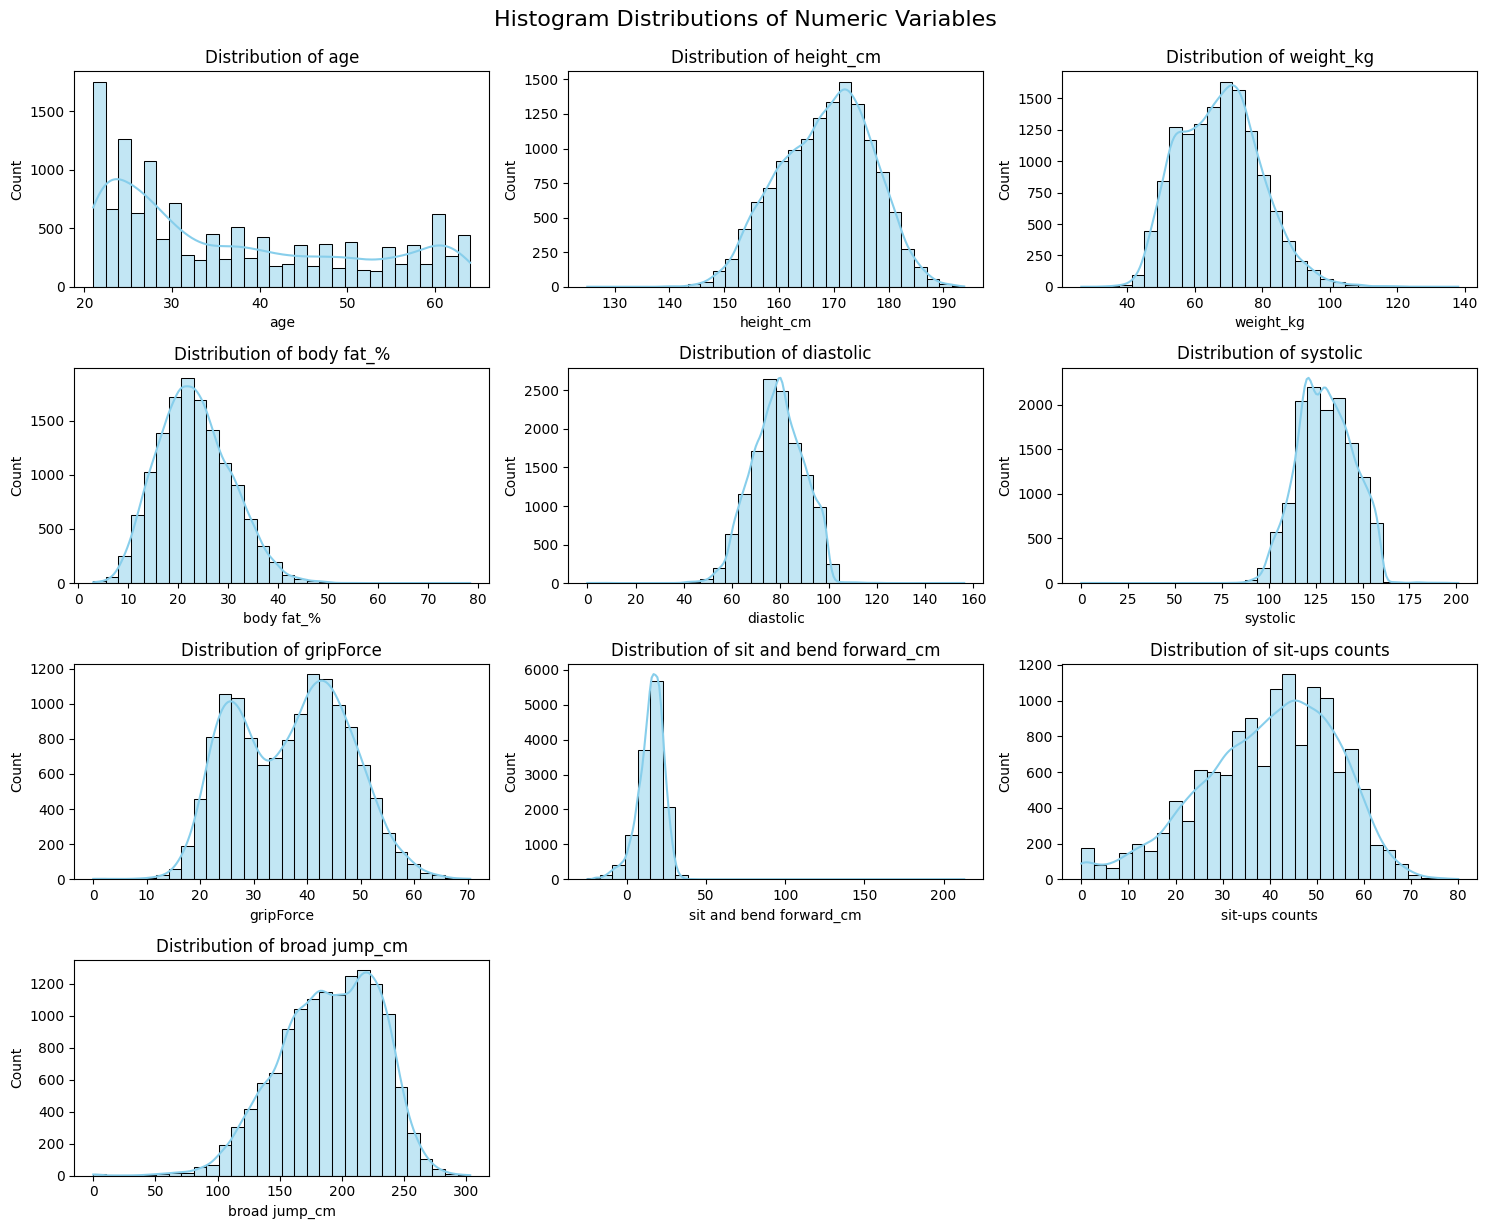

In [15]:
# 5.8 Distribution Analysis - Histograms for all numeric variables
# Select only numeric columns
numeric_cols = df.select_dtypes(include='number').columns

# Create histograms with KDE for better shape visualization
plt.figure(figsize=(15, 12))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(4, 3, i)
    sns.histplot(data=df, x=col, kde=True, bins=30, color='skyblue', edgecolor='black')
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')

plt.tight_layout()
plt.suptitle('Histogram Distributions of Numeric Variables', fontsize=16, y=1.02)
plt.show()

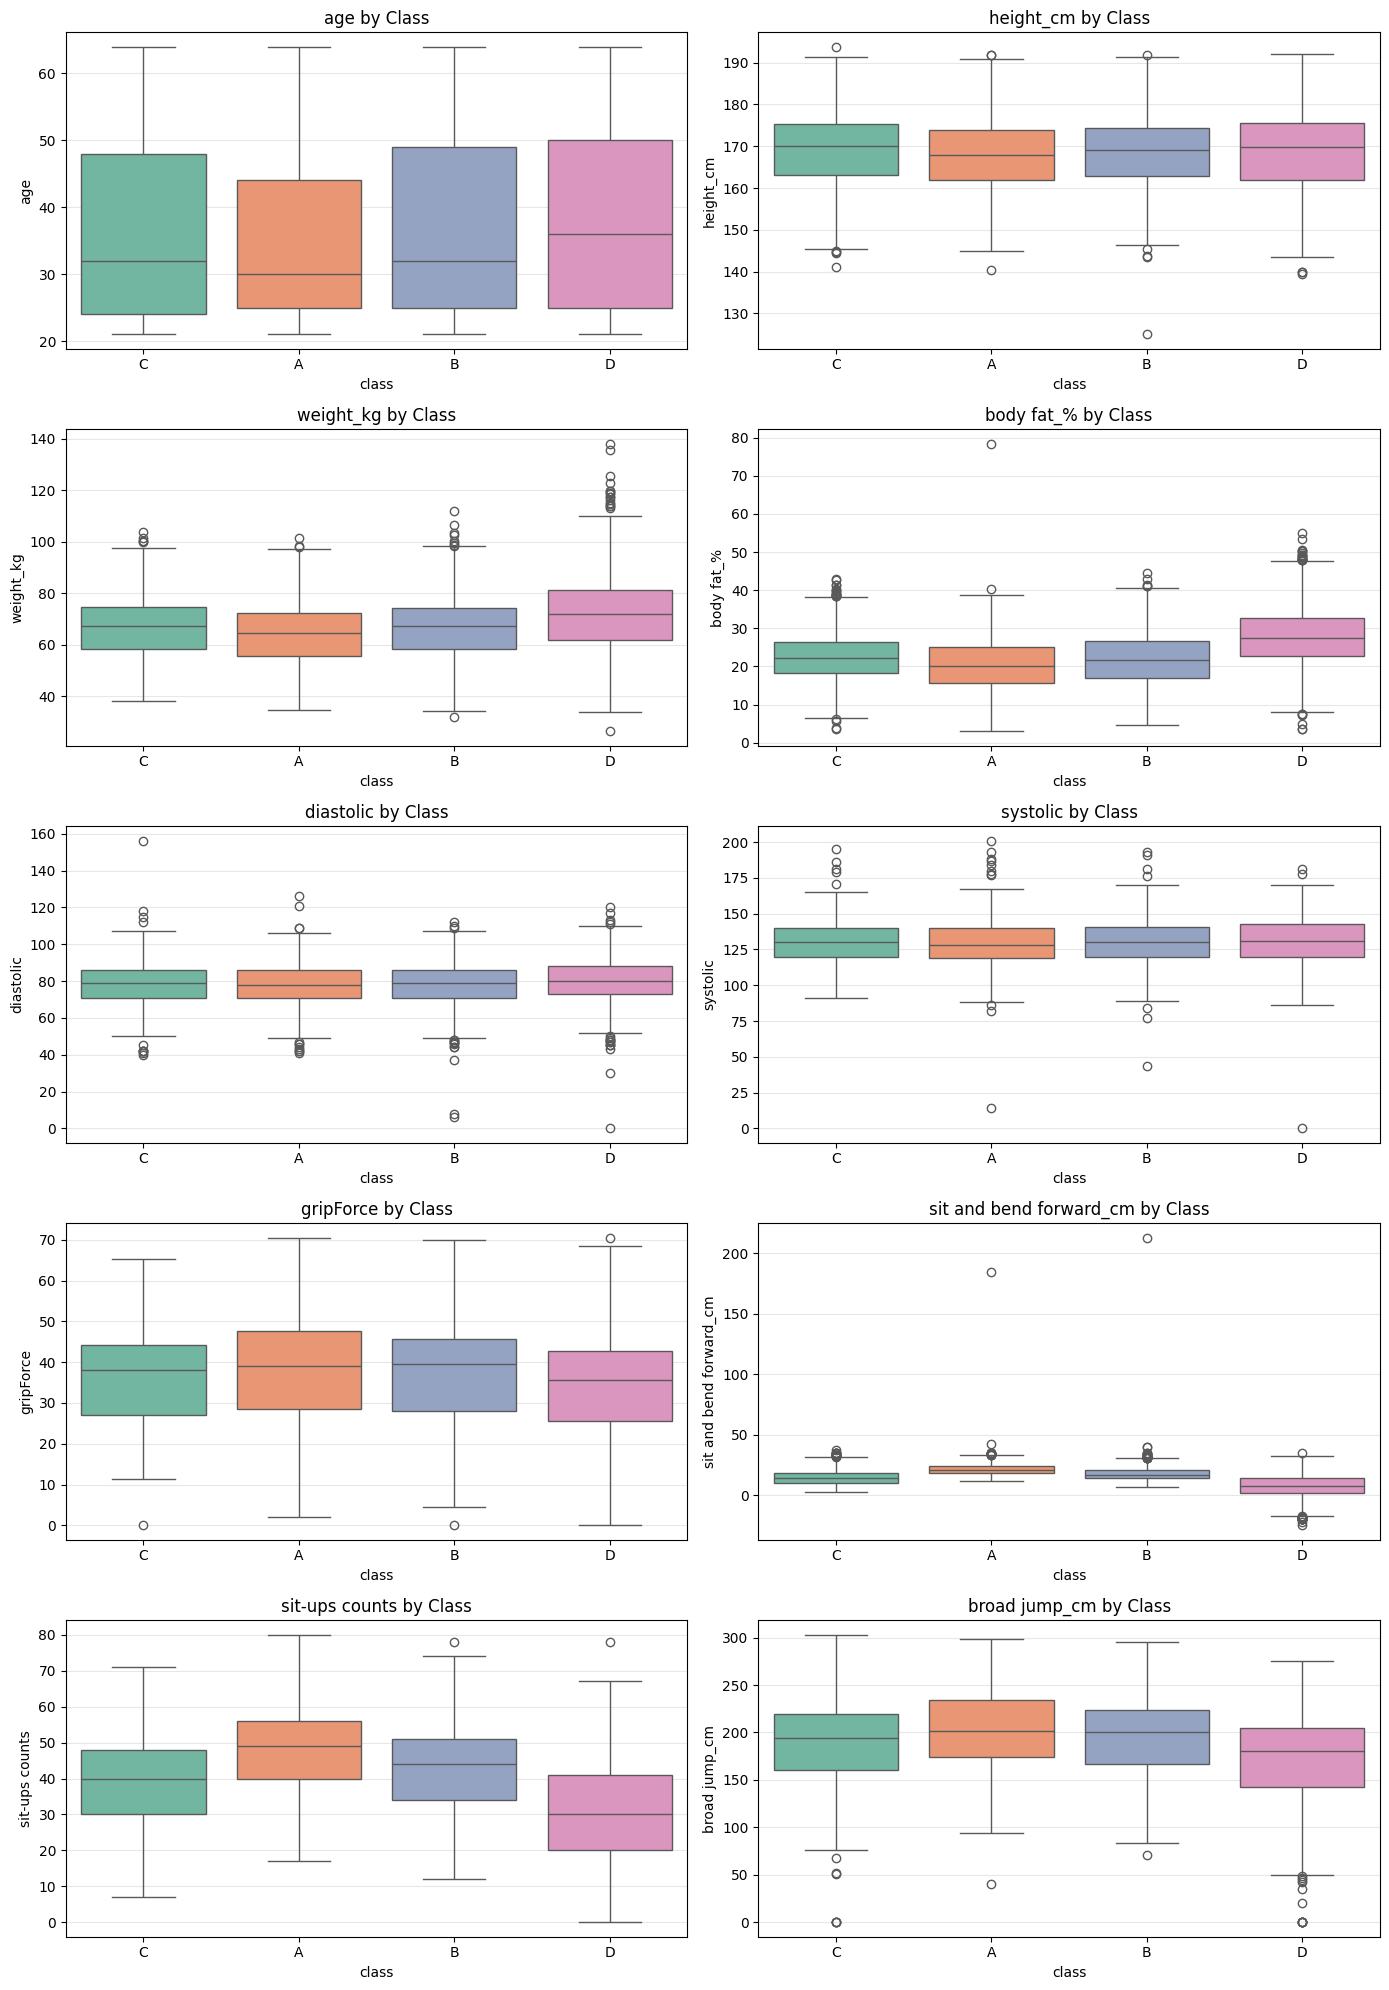

In [16]:

features = ['age', 'height_cm', 'weight_kg', 'body fat_%', 'diastolic', 'systolic',
            'gripForce', 'sit and bend forward_cm', 'sit-ups counts', 'broad jump_cm']
fig, axes = plt.subplots(5, 2, figsize=(14, 20))
axes = axes.ravel()
for i, f in enumerate(features):
    sns.boxplot(data=df, x="class", y=f, hue="class", palette="Set2", legend=False, ax=axes[i])
    axes[i].set_title(f"{f} by Class")
    axes[i].grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

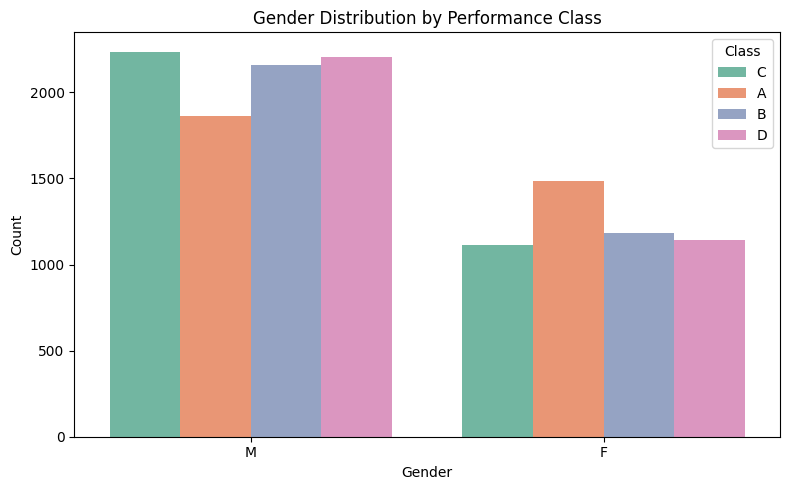

In [17]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='gender', hue='class', palette='Set2')
plt.title('Gender Distribution by Performance Class')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.legend(title='Class')
plt.tight_layout()
plt.show()

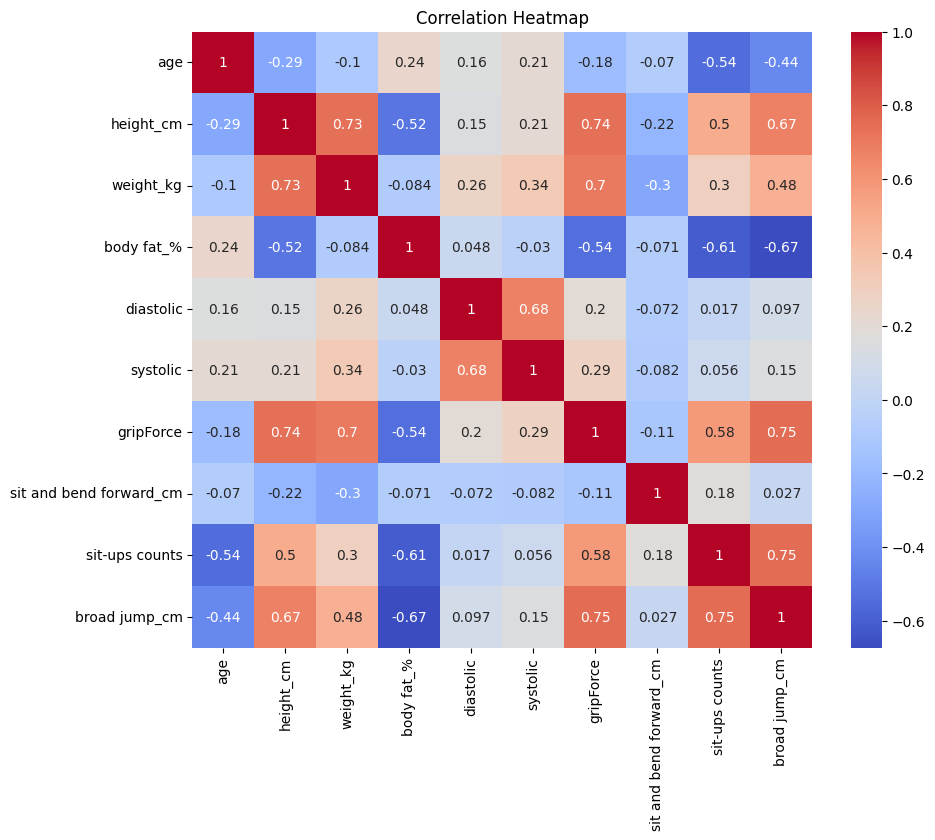

In [18]:
plt.figure(figsize=(10,8))
numeric_df = df.select_dtypes(include=['float64','int64'])
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

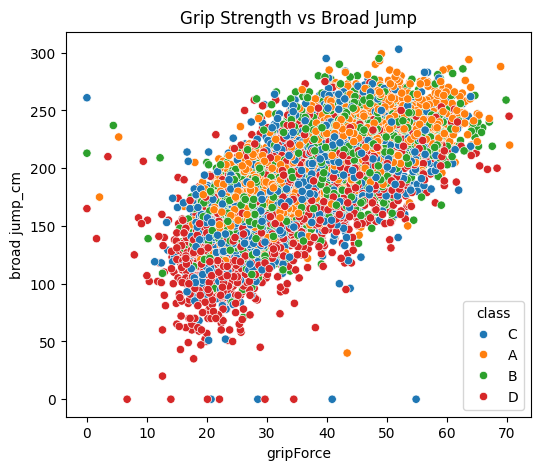

In [19]:
plt.figure(figsize=(6,5))
sns.scatterplot(data=df, x="gripForce", y="broad jump_cm", hue="class")
plt.title("Grip Strength vs Broad Jump")
plt.show()

In [20]:
# ─── 5.11 Final EDA Summary ───

print("""
Final EDA Summary

Five key insights:
1. Age negatively correlates with performance metrics (older → lower strength/power).
2. Males show higher gripForce, broad jump, sit-ups than females.
3. Height & weight strongly correlated (~0.74).
4. Higher body fat % linked to lower performance in strength/power tests.
5. Class A has best values in almost all fitness indicators.

Five potential data quality problems:
1. Zero values in performance metrics (gripForce, sit-ups, broad jump).
2. Extreme outliers in body fat_% and flexibility.
3. Mild positive skew in body fat_% and systolic BP.
4. Some negative flexibility values.
5. No missing values/duplicates after cleaning, but zeros/outliers need attention.

Recommended preprocessing steps:
- StandardScaler on numeric features (for KNN, SVM, NN)
- Keep outliers (realistic extremes)
- LabelEncode gender & class
- No imputation or duplicate removal needed
""")


Final EDA Summary

Five key insights:
1. Age negatively correlates with performance metrics (older → lower strength/power).
2. Males show higher gripForce, broad jump, sit-ups than females.
3. Height & weight strongly correlated (~0.74).
4. Higher body fat % linked to lower performance in strength/power tests.
5. Class A has best values in almost all fitness indicators.

Five potential data quality problems:
1. Zero values in performance metrics (gripForce, sit-ups, broad jump).
2. Extreme outliers in body fat_% and flexibility.
3. Mild positive skew in body fat_% and systolic BP.
4. Some negative flexibility values.
5. No missing values/duplicates after cleaning, but zeros/outliers need attention.

Recommended preprocessing steps:
- StandardScaler on numeric features (for KNN, SVM, NN)
- Keep outliers (realistic extremes)
- LabelEncode gender & class
- No imputation or duplicate removal needed



Machine learning models require numerical inputs. Therefore, categorical variables such as gender and the target class were converted into numerical form using Label Encoding. This transformation allows the neural network to process the data correctly during training.

In [21]:
df.select_dtypes(include="object").columns

Index(['gender', 'class'], dtype='object')

In [22]:
# Encode categorical variables before building the model

from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

df["gender"] = encoder.fit_transform(df["gender"])
df["class"] = encoder.fit_transform(df["class"])

In [34]:
df.dtypes

,0
age,float64
gender,int64
height_cm,float64
weight_kg,float64
body fat_%,float64
diastolic,float64
systolic,float64
gripForce,float64
sit and bend forward_cm,float64
sit-ups counts,float64


## Neural Network Model


In this section, a Neural Network model is implemented to classify the physical performance class of participants based on physiological and fitness measurements.

A new feature, Body Mass Index (BMI), was created from height and weight measurements.
 BMI is commonly used in health and fitness analysis and may provide additional information about body composition.



In [23]:
# Create a separate dataset for Neural Network

df_nn = df.copy()

# Create BMI feature
df_nn["BMI"] = df_nn["weight_kg"] / ((df_nn["height_cm"] / 100) ** 2)

# Add strength ratio (VERY IMPORTANT)
df_nn["strength_ratio"] = df_nn["gripForce"] / df_nn["weight_kg"]

Step 1 — Prepare Features and Target

The dataset was divided into input features (X) and the target variable (y). The goal of the neural network is to predict the performance class based on the physical attributes of each participant.


In [24]:
# Separate the input features (X) and the target variable (y)

X = df_nn.drop("class", axis=1)   # All columns except the target
y = df_nn["class"]                # Target variable (performance class)

Step 2 — Train Test Split

The dataset was split into training and testing sets. The training data is used to train the neural network, while the testing data evaluates the model's performance on unseen data.

In [25]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
# 80% for training and 20% for testing

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Step 3 — Feature Scaling

Feature scaling was applied to normalize the numerical variables. This improves neural network training stability and helps the model converge faster.


In [26]:
from sklearn.preprocessing import StandardScaler

# Create a scaler object
scaler = StandardScaler()

# Fit scaler on training data and transform both datasets
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Step 4 — Build the Neural Network

The neural network consists of two hidden layers with 64 and 32 neurons respectively. The ReLU activation function is used to introduce non-linearity, and the Adam optimizer is used to update the network weights during training.

In [27]:
from sklearn.neural_network import MLPClassifier

# Create the neural network model

nn_model = MLPClassifier(
   hidden_layer_sizes=(100,),   # simpler = better here
    activation='relu',   # Activation function
    solver='adam',                # Optimization algorithm
    max_iter=2000,               # Maximum training iterations
    alpha=0.0005,
    learning_rate_init=0.001,
    random_state=42
)

Step 5 — Train the Neural Network

During training, the neural network adjusts its weights and biases to minimize prediction error using the training data.

In [28]:
# Train the neural network using the training dataset

nn_model.fit(X_train_scaled, y_train)

MLPClassifier(alpha=0.0005, max_iter=2000, random_state=42)

Step 6 — Make Predictions

After training, the neural network predicts the performance class for each sample in the test dataset.

In [29]:
# Predict the classes for the test dataset

y_pred = nn_model.predict(X_test_scaled)

Step 7 — Evaluate Model Accuracy

Accuracy measures the percentage of correct predictions made by the neural network on the test dataset.

In [30]:
from sklearn.metrics import accuracy_score

# Calculate model accuracy

accuracy = accuracy_score(y_test, y_pred)

print("Neural Network Accuracy:", accuracy)

Neural Network Accuracy: 0.7547592385218365
